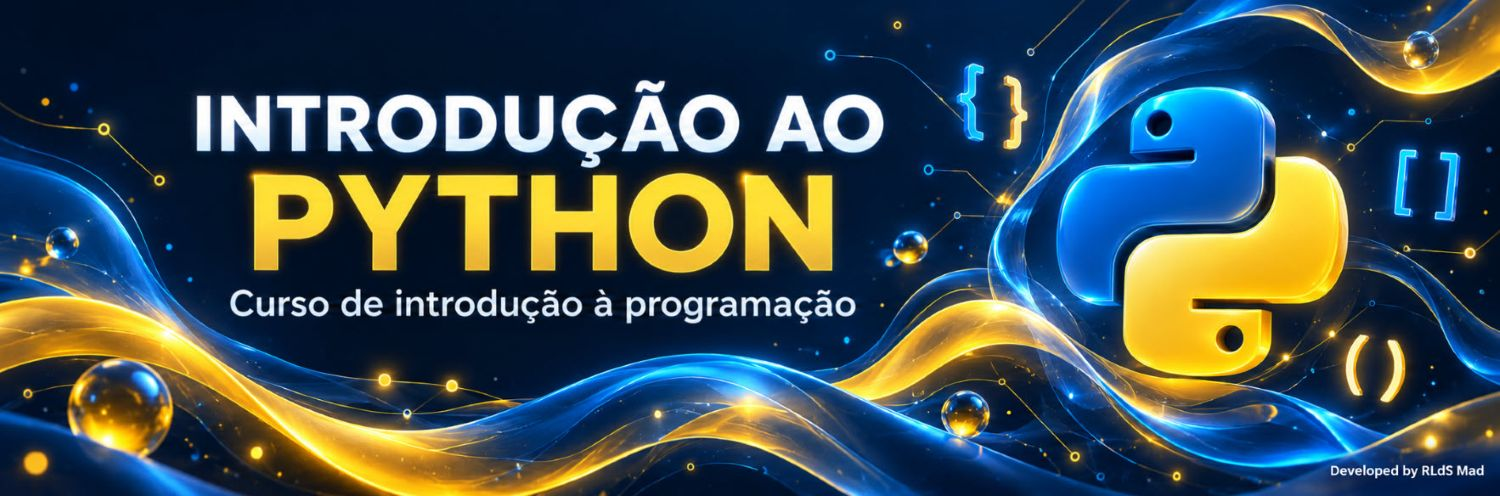

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_09_Aprender_a_Otimizar.ipynb)

# Nível IA · Módulo 9 – Aprender a otimizar
## Entropia cruzada, algoritmos genéticos e uma rede neuronal que imita a pesquisa tabu

No módulo anterior, os algoritmos de pesquisa resolviam o problema dos grupos de projeto com **regras fixas**: cada execução começava do zero e não aproveitava nada do que tinha visto antes. Neste módulo damos-lhes a capacidade de **aprender**, de três formas diferentes:

- o **método da entropia cruzada** aprende, durante a pesquisa, que pares de alunos aparecem juntos nas boas divisões, e usa esse conhecimento para gerar divisões melhores;
- um **algoritmo genético** mantém uma população de divisões e combina as melhores, como a seleção natural; a versão **memética** junta-lhe a pesquisa local;
- uma **rede neuronal** aprende com as escolhas feitas pela pesquisa tabu noutros problemas, e passa a prever que movimentos valem a pena, sem os avaliar todos.

No fim, comparamos tudo com a pesquisa tabu do N3_08 e respondemos à pergunta que interessa na prática: **quando é que aprender compensa?**

> **Objetivos:** distinguir pesquisa e aprendizagem em otimização; implementar o método da entropia cruzada e interpretar o modelo que ele aprende; implementar um algoritmo genético para problemas de agrupamento (seleção, cruzamento, mutação e elitismo) e a sua versão memética; treinar uma rede neuronal por imitação a partir das escolhas de um algoritmo e usá-la para guiar a pesquisa; avaliar a aprendizagem com dados nunca vistos e com um grupo de controlo; comparar métodos por avaliações e por tempo de CPU e decidir quando a aprendizagem compensa.

**Pré-requisitos:** o módulo N3_08 (o problema, a vizinhança, a avaliação incremental e a pesquisa tabu) e os módulos N3_04 ou N3_05 (o que é uma rede neuronal e como se treina). O scikit-learn é usado como no nível 2.

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas, ferramentas do N3_08 e vocabulário |
| 1. Pesquisar ou aprender? | o que muda quando um algoritmo aprende |
| 2. Método da entropia cruzada | aprender que pares funcionam juntos |
| 3. Algoritmos genéticos | população, cruzamento, mutação; versão memética |
| 4. Comparação com a pesquisa tabu | o mesmo tempo de CPU para todos |
| 5. Uma rede neuronal que imita a tabu | recolher exemplos, treinar, guiar a pesquisa |
| 6. Quando compensa aprender? | síntese e estado da arte |
| 7. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas e ferramentas do N3_08

A célula seguinte importa as bibliotecas e define as funções do N3_08 que vamos reutilizar: os dados, a representação, a solução gulosa, a classe `Estado` com a avaliação incremental, a vizinhança focada, o orçamento, a subida de colina e a pesquisa tabu. O código é exatamente o do módulo anterior, onde está explicado passo a passo; aqui só o executamos.

In [1]:
# Executar esta célula

import itertools
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# ----------------------------------------------------------------------------
# Ferramentas do N3_08 (sem alterações)
# ----------------------------------------------------------------------------
def gerar_incompatibilidades(n, semente=2026):
    # Matriz simétrica n x n com índices 0; 0,25; 0,5; 0,75 ou 1 e diagonal 0.
    rng = np.random.default_rng(semente)
    niveis = np.array([0, 0.25, 0.5, 0.75, 1])
    m = rng.choice(niveis, size=(120, 120), p=[0.05, 0.15, 0.30, 0.30, 0.20])
    m = np.triu(m, 1)  # só a parte acima da diagonal...
    return (m + m.T)[:n, :n]  # ...espelhada para baixo: fica simétrica


def e_valida(grupos, n, minimo=3, maximo=5):
    tamanhos_ok = all(minimo <= len(g) <= maximo for g in grupos)
    todos_uma_vez = sorted(a for g in grupos for a in g) == list(range(n))
    return tamanhos_ok and todos_uma_vez


def mostrar(grupos):
    # Grupos com os alunos numerados a partir de 1, ordenados para facilitar a leitura.
    return sorted(sorted(a + 1 for a in g) for g in grupos)


def incompatibilidade_grupo(A, grupo):
    return sum(A[i][j] for i, j in itertools.combinations(grupo, 2))


def valor_divisao(A, grupos):
    return max(incompatibilidade_grupo(A, g) for g in grupos)


def distribuicoes(n, minimo=3, maximo=5):
    resultado = []
    for k in range(math.ceil(n / maximo), n // minimo + 1):  # número de grupos possível
        for tamanhos in itertools.combinations_with_replacement(range(minimo, maximo + 1), k):
            if sum(tamanhos) == n:
                resultado.append(tamanhos)
    return resultado


def tamanhos_iniciais(n):
    maximo_grupos = max(len(d) for d in distribuicoes(n))
    return sorted(next(d for d in distribuicoes(n) if len(d) == maximo_grupos))


def divisao_aleatoria(n, rng):
    alunos = rng.permutation(n).tolist()
    grupos, inicio = [], 0
    for t in tamanhos_iniciais(n):
        grupos.append(alunos[inicio:inicio + t])
        inicio += t
    return grupos


def divisao_gulosa(A, n):
    tamanhos = tamanhos_iniciais(n)
    grupos = [[] for _ in tamanhos]
    custos = [0.0] * len(tamanhos)
    por_dificuldade = sorted(range(n), key=lambda a: sum(A[a]), reverse=True)
    for aluno in por_dificuldade:
        # Entre os grupos com lugar, o que fica com menor incompatibilidade (desempate: o mais vazio).
        melhor = min((custos[g] + sum(A[aluno][b] for b in grupos[g]), len(grupos[g]), g)
                     for g in range(len(grupos)) if len(grupos[g]) < tamanhos[g])
        novo_custo, _, g = melhor
        grupos[g].append(aluno)
        custos[g] = novo_custo
    return grupos


def ligacao(A, aluno, grupo, sem=None):
    # Soma dos índices entre `aluno` e os elementos de `grupo` (exceto ele próprio e `sem`).
    linha = A[aluno]
    return sum(linha[g] for g in grupo if g != aluno and g != sem)


class Estado:
    def __init__(self, A, grupos):
        self.A = A
        self.grupos = [list(g) for g in grupos]
        self.custos = [incompatibilidade_grupo(A, g) for g in self.grupos]

    def copia(self):
        novo = Estado.__new__(Estado)
        novo.A, novo.grupos, novo.custos = self.A, [g[:] for g in self.grupos], self.custos[:]
        return novo

    def valor(self):
        return max(self.custos)

    def custos_apos(self, movimento):
        tipo, i, x, j, y = movimento
        gi, gj = self.grupos[i], self.grupos[j]
        custos = self.custos[:]
        if tipo == "troca":
            custos[i] = self.custos[i] - ligacao(self.A, x, gi) + ligacao(self.A, y, gi, sem=x)
            custos[j] = self.custos[j] - ligacao(self.A, y, gj) + ligacao(self.A, x, gj, sem=y)
        else:  # transferência
            custos[i] = self.custos[i] - ligacao(self.A, x, gi)
            custos[j] = self.custos[j] + ligacao(self.A, x, gj)
        return custos

    def aplicar(self, movimento, custos):
        tipo, i, x, j, y = movimento
        if tipo == "troca":
            gi, gj = self.grupos[i], self.grupos[j]
            gi[gi.index(x)], gj[gj.index(y)] = y, x
        else:
            self.grupos[i].remove(x)
            self.grupos[j].append(x)
        self.custos = custos


def movimento_aleatorio(estado, rng):
    k = len(estado.grupos)
    i, j = (int(v) for v in rng.choice(k, 2, replace=False))
    gi, gj = estado.grupos[i], estado.grupos[j]
    x = gi[rng.integers(len(gi))]
    if rng.random() < 0.3 and len(gi) > 3 and len(gj) < 5:
        return ("transferência", i, x, j, None)
    return ("troca", i, x, j, gj[rng.integers(len(gj))])


def objetivo(custos):
    return (max(custos), sum(c * c for c in custos))


def vizinhanca(estado, focada=True):
    k = len(estado.grupos)
    pior = max(estado.custos)
    origens = [i for i in range(k) if estado.custos[i] >= pior - 1e-12] if focada else list(range(k))
    for i in origens:
        gi = estado.grupos[i]
        for j in range(k):
            if j == i:
                continue
            gj = estado.grupos[j]
            if not (j in origens and j < i):  # não repetir a troca i<->j
                for x in gi:
                    for y in gj:
                        yield ("troca", i, x, j, y)
            if len(gi) > 3 and len(gj) < 5:
                for x in gi:
                    yield ("transferência", i, x, j, None)


class Orcamento:
    def __init__(self, max_avaliacoes=1_000_000, max_cpu=30.0):
        self.max_avaliacoes = max_avaliacoes
        self.max_cpu = max_cpu
        self.avaliacoes = 0
        self.inicio = time.process_time()
        self._proxima_verificacao = 1000
        self._esgotado = False

    def gastar(self, n=1):
        self.avaliacoes += n

    def esgotado(self):
        if not self._esgotado:
            if self.avaliacoes >= self.max_avaliacoes:
                self._esgotado = True
            elif self.avaliacoes >= self._proxima_verificacao:  # ver o relógio só de 1000 em 1000
                self._proxima_verificacao = self.avaliacoes + 1000
                self._esgotado = self.cpu() >= self.max_cpu
        return self._esgotado  # depois de esgotado, fica esgotado

    def cpu(self):
        return time.process_time() - self.inicio


def subida_colina(A, grupos, orcamento, focada=True):
    estado = Estado(A, grupos)
    atual = objetivo(estado.custos)
    historico = [(orcamento.avaliacoes, atual[0])]
    iteracoes = 0
    while not orcamento.esgotado():
        melhor = None
        for mov in vizinhanca(estado, focada):
            if orcamento.esgotado():
                break
            custos = estado.custos_apos(mov)
            orcamento.gastar()
            ob = objetivo(custos)
            if ob < atual and (melhor is None or ob < melhor[0]):
                melhor = (ob, mov, custos)
        if melhor is None:  # nenhum vizinho melhor: ótimo local
            break
        atual, mov, custos = melhor
        estado.aplicar(mov, custos)
        iteracoes += 1
        historico.append((orcamento.avaliacoes, atual[0]))
    return estado, {"iterações": iteracoes}, historico


def pesquisa_tabu(A, grupos, orcamento, duracao=7, focada=True):
    estado = Estado(A, grupos)
    melhor, ob_melhor = estado.copia(), objetivo(estado.custos)
    proibido = {}  # (aluno, grupo) -> última iteração em que o aluno não pode voltar a esse grupo
    historico = [(orcamento.avaliacoes, ob_melhor[0])]
    iteracao = 0
    while not orcamento.esgotado():
        escolhido = None
        for mov in vizinhanca(estado, focada):
            if orcamento.esgotado():
                break
            custos = estado.custos_apos(mov)
            orcamento.gastar()
            ob = objetivo(custos)
            _, i, x, j, y = mov
            tabu = proibido.get((x, j), -1) >= iteracao or (y is not None and proibido.get((y, i), -1) >= iteracao)
            if tabu and not ob < ob_melhor:  # critério de aspiração
                continue
            if escolhido is None or ob < escolhido[0]:
                escolhido = (ob, mov, custos)
        if escolhido is None:  # todos os movimentos tabu (ou orçamento esgotado a meio)
            break
        ob, mov, custos = escolhido
        _, i, x, j, y = mov
        estado.aplicar(mov, custos)
        proibido[(x, i)] = iteracao + duracao  # x não volta já ao grupo i
        if y is not None:
            proibido[(y, j)] = iteracao + duracao  # nem y ao grupo j
        iteracao += 1
        if ob < ob_melhor:
            melhor, ob_melhor = estado.copia(), ob
            historico.append((orcamento.avaliacoes, ob[0]))
    historico.append((orcamento.avaliacoes, ob_melhor[0]))
    return melhor, {"iterações": iteracao}, historico


CENARIOS = {1: 6, 2: 12, 3: 24, 4: 60, 5: 120}
REFERENCIA_N3_08 = {2: 1.5, 3: 1.0, 4: 0.75, 5: 0.5}  # melhores valores do N3_08 (cenário 2: ótimo)
print("Ferramentas do N3_08 prontas.")

Ferramentas do N3_08 prontas.


### 0.2 Vocabulário

| Termo | Significado neste módulo |
| --- | --- |
| **População** | um conjunto de soluções mantidas ao mesmo tempo |
| **Geração** | uma iteração de um algoritmo de população: avaliar, selecionar e criar a população seguinte |
| **Elite** | as melhores soluções de uma geração |
| **Modelo probabilístico** | uma regra que diz com que probabilidade se gera cada solução; no método da entropia cruzada, é uma matriz de afinidades entre alunos |
| **Cruzamento** | criar uma solução nova (filho) a partir de duas existentes (pais) |
| **Mutação** | uma alteração aleatória pequena num filho |
| **Característica** (*feature*) | um número que descreve um movimento e que a rede neuronal recebe como entrada |
| **Rótulo** | a resposta certa num exemplo de treino; aqui, se um movimento é bom (1) ou não (0) |
| **Aprendizagem por imitação** | treinar um modelo para reproduzir as decisões de um especialista (aqui, a pesquisa tabu) |

## 1. Pesquisar ou aprender?

A pesquisa tabu do N3_08 é inteligente, mas **não aprende**. Em cada iteração avalia centenas de movimentos e escolhe um, e na iteração seguinte faz o mesmo, sem tirar partido do que viu. Se a corrermos amanhã noutra turma, começa do zero.

Há duas formas de juntar aprendizagem à otimização:

| | Aprender **durante** a pesquisa | Aprender **entre** problemas |
| --- | --- | --- |
| O que se aprende | que características têm as boas soluções **deste** problema | que decisões costumam ser boas **neste tipo** de problema |
| Quando | enquanto se resolve; o que se aprende serve só para este problema | antes, a partir de problemas já resolvidos; serve para problemas novos |
| Exemplos neste módulo | entropia cruzada, algoritmo genético | rede neuronal que imita a tabu |

Ambas as abordagens têm um custo: o tempo gasto a aprender não é gasto a pesquisar. A pergunta de fundo deste módulo é se esse investimento compensa.

## 2. Método da entropia cruzada

### 2.1 A ideia

O **método da entropia cruzada** (*cross-entropy method*, Rubinstein, 1999) é talvez a forma mais simples de um algoritmo de otimização aprender. Mantém um **modelo probabilístico** que gera soluções e repete quatro passos:

```text
modelo ← uniforme (todas as soluções igualmente prováveis)
repetir:
    1. amostrar: gerar uma população de soluções com o modelo
    2. avaliar: calcular o valor de cada uma
    3. selecionar: ficar com a elite (as melhores)
    4. aprender: ajustar o modelo para que gere soluções parecidas com a elite
```

Com o tempo, o modelo concentra-se nas zonas boas do espaço de soluções. O nome vem da medida que, em teoria, o passo 4 minimiza (a entropia cruzada entre o modelo e a distribuição da elite), mas não precisamos dessa teoria para o usar.

### 2.2 O modelo: uma matriz de afinidades

Para o nosso problema, o modelo é uma matriz $P$ de **afinidades**: $P_{ab}$ diz o quanto os alunos $a$ e $b$ «costumam» ficar juntos nas boas divisões. Para gerar uma divisão com o modelo:

1. escolhe-se ao acaso um aluno livre para abrir um grupo;
2. cada colega seguinte é sorteado entre os alunos livres, com probabilidade proporcional ao produto das suas afinidades com quem já está no grupo;
3. repete-se até todos os alunos terem grupo (com os tamanhos da solução gulosa do N3_08).

Usar o **produto** das afinidades faz com que um candidato só seja provável se for compatível com **todos** os membros do grupo, e não só com um.

In [2]:
# Executar esta célula

def amostrar_divisao(P, tamanhos, rng):
    n = len(P)
    livre = np.ones(n, dtype=bool)
    grupos = []
    for t in rng.permutation(tamanhos):
        candidatos = np.flatnonzero(livre)
        primeiro = int(candidatos[rng.integers(len(candidatos))])
        grupo = [primeiro]
        livre[primeiro] = False
        peso = P[primeiro].copy()  # produto das afinidades com os membros do grupo
        for _ in range(t - 1):
            candidatos = np.flatnonzero(livre)
            w = peso[candidatos] / peso[candidatos].sum()
            escolhido = int(candidatos[rng.choice(len(candidatos), p=w)])
            grupo.append(escolhido)
            livre[escolhido] = False
            peso *= P[escolhido]
        grupos.append(grupo)
    return grupos


P_uniforme = np.full((6, 6), 0.5)
print(mostrar(amostrar_divisao(P_uniforme, [3, 3], np.random.default_rng(0))))

[[1, 2, 4], [3, 5, 6]]


### 2.3 Aprender com a elite

Depois de avaliar a população, contamos, para cada par de alunos, em quantas divisões da elite ficaram juntos. Essa frequência $W_{ab}$ (entre 0 e 1) é o que a elite «ensina». O modelo é atualizado com uma média entre o que sabia e o que aprendeu:

$$P \leftarrow (1-\alpha)\,P + \alpha\,(W + \varepsilon)$$

- $\alpha$ é a **taxa de aprendizagem**: com $\alpha$ perto de 1, o modelo esquece depressa o passado; com $\alpha$ pequeno, aprende devagar.
- $\varepsilon$ é uma pequena **margem de exploração**: sem ela, um par que nunca apareceu na elite ficaria com afinidade zero e nunca mais seria experimentado.

In [3]:
# Executar esta célula

def entropia_cruzada(A, n, orcamento, rng, populacao=100, elite=10, alfa=0.5, eps=0.02, guardar_modelo=()):
    tamanhos = tamanhos_iniciais(n)
    P = np.full((n, n), 0.5)
    np.fill_diagonal(P, 0)
    melhor, ob_melhor = None, (math.inf, math.inf)
    historico, modelos = [], {}
    geracao = 0
    while not orcamento.esgotado():
        # 1-2. amostrar e avaliar
        amostras = []
        for _ in range(populacao):
            divisao = amostrar_divisao(P, tamanhos, rng)
            orcamento.gastar()
            amostras.append((objetivo([incompatibilidade_grupo(A, g) for g in divisao]), divisao))
            if orcamento.esgotado():
                break
        # 3. selecionar a elite
        amostras.sort(key=lambda s: s[0])
        if amostras[0][0] < ob_melhor:
            ob_melhor, melhor = amostras[0]
        # 4. aprender: frequência com que cada par fica junto na elite
        W = np.zeros((n, n))
        for _, divisao in amostras[:elite]:
            for g in divisao:
                W[np.ix_(g, g)] += 1
        W /= min(elite, len(amostras))
        P = (1 - alfa) * P + alfa * (W + eps)
        np.fill_diagonal(P, 0)
        geracao += 1
        historico.append((orcamento.avaliacoes, ob_melhor[0]))
        if geracao in guardar_modelo:
            modelos[geracao] = P.copy()
    return melhor, ob_melhor[0], {"gerações": geracao}, historico, modelos

### 2.4 Ver o modelo a aprender

Começamos pelo cenário 2 (12 alunos), em que sabemos do N3_08 que o ótimo vale 1,5. Guardamos o modelo em três momentos e desenhamo-lo como um mapa de calor: cada quadrado é a afinidade entre dois alunos. Para se ver melhor, os alunos aparecem ordenados pelos grupos da melhor divisão encontrada.

Melhor valor: 1.5 (ótimo: 1,5) | 200 gerações | 20000 avaliações | 2.8 s
Melhor divisão: [[1, 8, 10], [2, 3, 9], [4, 6, 12], [5, 7, 11]]


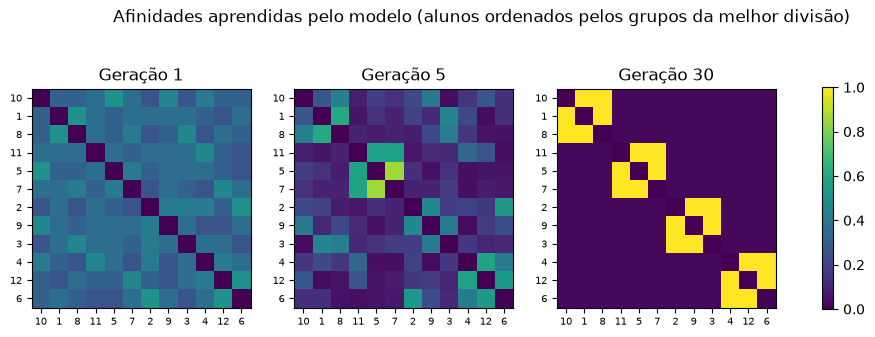

In [4]:
# Executar esta célula

A12 = gerar_incompatibilidades(12).tolist()
orc = Orcamento(max_avaliacoes=20_000)
divisao, valor, info, hist, modelos = entropia_cruzada(A12, 12, orc, np.random.default_rng(0), guardar_modelo=(1, 5, 30))
print(f"Melhor valor: {valor} (ótimo: 1,5) | {info['gerações']} gerações | {orc.avaliacoes} avaliações | {orc.cpu():.1f} s")
print("Melhor divisão:", mostrar(divisao))

ordem = [a for g in divisao for a in g]  # alunos ordenados pelos grupos encontrados
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (geracao, P) in zip(eixos, modelos.items()):
    im = ax.imshow(P[np.ix_(ordem, ordem)], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Geração {geracao}")
    ax.set_xticks(range(12), [a + 1 for a in ordem], fontsize=7)
    ax.set_yticks(range(12), [a + 1 for a in ordem], fontsize=7)
    ax.grid(False)
fig.suptitle("Afinidades aprendidas pelo modelo (alunos ordenados pelos grupos da melhor divisão)", y=1.02)
fig.colorbar(im, ax=eixos, shrink=0.8)
plt.show()

Depois de uma geração, o modelo ainda é quase uniforme. Ao fim de cinco já se distinguem alguns pares e, ao fim de trinta, a matriz mostra quatro blocos nítidos ao longo da diagonal: os quatro grupos da divisão que o modelo «aprendeu». Ao contrário da pesquisa tabu, o método da entropia cruzada deixa ver **o que aprendeu** sobre o problema: que alunos ficam bem juntos.

### 2.5 Num problema maior

No cenário 3 (24 alunos), damos-lhe 5 segundos de CPU:

In [5]:
# Executar esta célula

A24 = gerar_incompatibilidades(24).tolist()
for semente in range(3):
    orc = Orcamento(max_avaliacoes=10**9, max_cpu=5)
    _, valor, info, _, _ = entropia_cruzada(A24, 24, orc, np.random.default_rng(semente))
    print(f"Semente {semente}: valor {valor} | {info['gerações']} gerações | {orc.avaliacoes} avaliações")
print("Pesquisa tabu (N3_08):", REFERENCIA_N3_08[3])

Semente 0: valor 1.25 | 170 gerações | 17000 avaliações


Semente 1: valor 1.0 | 170 gerações | 17000 avaliações


Semente 2: valor 1.0 | 170 gerações | 17000 avaliações
Pesquisa tabu (N3_08): 1.0


O método da entropia cruzada nem sempre chega ao valor da pesquisa tabu, e tem dois pontos fracos:

- **Convergência prematura:** quando a elite se parece demasiado consigo própria, o modelo fixa-se numa zona do espaço e deixa de explorar. A taxa $\alpha$ e a margem $\varepsilon$ controlam este equilíbrio (exercício 1).
- **Cada avaliação é cara:** cada amostra é uma divisão completa, gerada e avaliada do zero. A pesquisa tabu avalia movimentos de forma incremental, muito mais depressa. Por isso, com o mesmo tempo, a tabu faz muitas mais avaliações.

## 3. Algoritmos genéticos

### 3.1 A ideia

Um **algoritmo genético** (Holland, 1975) imita a evolução natural. Mantém uma **população** de soluções e, em cada **geração**:

1. **seleciona** pais, dando mais hipóteses às melhores soluções;
2. **cruza** os pais para criar filhos que combinam características de ambos;
3. **muta** alguns filhos com pequenas alterações aleatórias;
4. forma a nova população com os filhos e as melhores soluções da anterior (**elitismo**).

A aprendizagem está na população: as boas características sobrevivem e combinam-se de geração em geração.

### 3.2 Cruzar divisões em grupos

O cruzamento é a parte delicada. Se representássemos uma divisão como uma lista de alunos e cortássemos as listas dos dois pais ao meio, como num algoritmo genético clássico, os filhos teriam alunos repetidos e grupos desfeitos. Neste problema, o que tem valor são os **grupos**, por isso o cruzamento deve passá-los inteiros de pais para filhos (é a ideia dos algoritmos genéticos de agrupamento de Falkenauer):

1. o filho herda metade dos grupos do primeiro pai, escolhidos ao acaso;
2. herda depois os grupos do segundo pai que não tenham alunos já usados;
3. os alunos que sobram são **reparados**: cada um vai para o grupo com lugar onde aumenta menos a incompatibilidade; se não houver lugar, forma-se um grupo novo.

A mutação é um movimento aleatório do N3_08 (uma troca ou uma transferência). A seleção é por **torneio**: sorteiam-se duas soluções e fica a melhor.

In [6]:
# Executar esta célula

def cruzamento(A, pai1, pai2, rng):
    k = len(pai1)
    filho = [list(pai1[i]) for i in rng.permutation(k)[: k // 2]]  # 1. metade dos grupos do pai 1
    usados = {a for g in filho for a in g}
    for i in rng.permutation(len(pai2)):  # 2. grupos compatíveis do pai 2
        if not any(a in usados for a in pai2[i]):
            filho.append(list(pai2[i]))
            usados.update(pai2[i])
    n = sum(len(g) for g in pai1)
    sobra = [a for a in range(n) if a not in usados]  # 3. reparação
    rng.shuffle(sobra)
    while sobra:
        aluno = sobra.pop()
        com_lugar = [(sum(A[aluno][b] for b in g), i) for i, g in enumerate(filho) if len(g) < 5]
        if com_lugar:
            filho[min(com_lugar)[1]].append(aluno)
        else:
            novo = [aluno]
            while len(novo) < 3:  # completar o grupo novo (com sobras ou tirando de grupos grandes)
                if sobra:
                    novo.append(sobra.pop())
                else:
                    maior = max(range(len(filho)), key=lambda i: len(filho[i]))
                    novo.append(filho[maior].pop())
            filho.append(novo)
    return filho


def mutacao(grupos, rng):
    estado = Estado.__new__(Estado)
    estado.grupos = [g[:] for g in grupos]
    tipo, i, x, j, y = movimento_aleatorio(estado, rng)
    gi, gj = estado.grupos[i], estado.grupos[j]
    if tipo == "troca":
        gi[gi.index(x)], gj[gj.index(y)] = y, x
    else:
        gi.remove(x)
        gj.append(x)
    return estado.grupos


rng = np.random.default_rng(1)
pai1, pai2 = divisao_aleatoria(12, rng), divisao_aleatoria(12, rng)
filho = cruzamento(A12, pai1, pai2, rng)
print("Pai 1: ", mostrar(pai1), valor_divisao(A12, pai1))
print("Pai 2: ", mostrar(pai2), valor_divisao(A12, pai2))
print("Filho: ", mostrar(filho), valor_divisao(A12, filho), "| válido:", e_valida(filho, 12))

Pai 1:  [[1, 6, 8], [2, 3, 10], [4, 7, 11], [5, 9, 12]] 2.5
Pai 2:  [[1, 5, 8], [2, 4, 7], [3, 11, 12], [6, 9, 10]] 2.25
Filho:  [[1, 5, 8], [2, 3, 6, 9, 10], [4, 7, 11, 12]] 4.75 | válido: True


O filho é válido, mas pode ser pior do que os dois pais: os grupos herdados são bons, mas a reparação junta os alunos que sobram como pode. O cruzamento não garante filhos melhores; é a **seleção**, geração após geração, que fica com os bons e descarta os maus.

### 3.3 O algoritmo completo e a versão memética

Juntamos as peças. Com `memetico=0.1`, cada filho tem 10 % de probabilidade de ser melhorado por uma subida de colina antes de entrar na população. É o **algoritmo memético** (Moscato, 1989): o algoritmo genético explora o espaço, e a pesquisa local afina as soluções.

In [7]:
# Executar esta célula

def algoritmo_genetico(A, n, orcamento, rng, populacao=40, elite=2, p_mutacao=0.3, memetico=0.0):
    def avaliar(divisao):
        orcamento.gastar()
        return objetivo([incompatibilidade_grupo(A, g) for g in divisao])

    def torneio():
        a, b = rng.integers(populacao, size=2)
        return pop[a] if aptidao[a] < aptidao[b] else pop[b]

    pop = [divisao_aleatoria(n, rng) for _ in range(populacao)]
    aptidao = [avaliar(d) for d in pop]
    geracao, historico = 0, []
    while not orcamento.esgotado():
        ordem = sorted(range(populacao), key=lambda i: aptidao[i])
        nova_pop = [pop[i] for i in ordem[:elite]]  # elitismo: as melhores passam diretamente
        nova_apt = [aptidao[i] for i in ordem[:elite]]
        while len(nova_pop) < populacao and not orcamento.esgotado():
            filho = cruzamento(A, torneio(), torneio(), rng)
            if rng.random() < p_mutacao:
                filho = mutacao(filho, rng)
            if memetico and rng.random() < memetico:
                filho = subida_colina(A, filho, orcamento)[0].grupos
            nova_pop.append(filho)
            nova_apt.append(avaliar(filho))
        if len(nova_pop) == populacao:  # só substitui gerações completas
            pop, aptidao = nova_pop, nova_apt
        geracao += 1
        historico.append((orcamento.avaliacoes, min(aptidao)[0]))
    i = min(range(populacao), key=lambda i: aptidao[i])
    return pop[i], aptidao[i][0], {"gerações": geracao}, historico


for memetico in (0.0, 0.1):
    orc = Orcamento(max_avaliacoes=10**9, max_cpu=5)
    divisao, valor, info, _ = algoritmo_genetico(A24, 24, orc, np.random.default_rng(0), memetico=memetico)
    assert e_valida(divisao, 24)
    nome = "memético" if memetico else "genético"
    print(f"Algoritmo {nome}: valor {valor} | {info['gerações']} gerações | {orc.avaliacoes} avaliações")

Algoritmo genético: valor 1.25 | 2473 gerações | 94000 avaliações


Algoritmo memético: valor 1.75 | 285 gerações | 990001 avaliações


## 4. Comparação com a pesquisa tabu

No N3_08 comparámos algoritmos pelo **número de avaliações**. Aqui isso seria injusto: uma avaliação da entropia cruzada ou do algoritmo genético é uma divisão completa, enquanto uma avaliação da tabu é um movimento calculado de forma incremental, muito mais barato. Por isso damos a todos o mesmo **tempo de CPU**: 5 segundos por execução, duas sementes, nos cenários 3 e 4. Todos partem de soluções aleatórias. Esta célula demora cerca de 40 segundos.

In [8]:
# Executar esta célula

METODOS = {
    "entropia cruzada": lambda A, n, orc, rng: entropia_cruzada(A, n, orc, rng)[1],
    "algoritmo genético": lambda A, n, orc, rng: algoritmo_genetico(A, n, orc, rng)[1],
    "algoritmo memético": lambda A, n, orc, rng: algoritmo_genetico(A, n, orc, rng, memetico=0.1)[1],
    "pesquisa tabu": lambda A, n, orc, rng: pesquisa_tabu(A, divisao_aleatoria(n, rng), orc)[0].valor(),
}
linhas = []
for cenario in (3, 4):
    n = CENARIOS[cenario]
    A = gerar_incompatibilidades(n).tolist()
    for nome, metodo in METODOS.items():
        for semente in range(2):
            orc = Orcamento(max_avaliacoes=10**9, max_cpu=5)
            linhas.append({"cenário": cenario, "método": nome, "semente": semente,
                           "valor": metodo(A, n, orc, np.random.default_rng(semente)), "avaliações": orc.avaliacoes})
comparacao = pd.DataFrame(linhas)
comparacao.pivot_table(index="método", columns="cenário", values=["valor", "avaliações"], aggfunc="mean").round(2)

avaliações            valor      
cenário                     3          4     3     4
método                                              
algoritmo genético    96000.0    54500.0  1.25  1.62
algoritmo memético  1132501.0  1110501.5  1.50  1.00
entropia cruzada      18000.0     8000.0  1.12  1.75
pesquisa tabu       1178000.0  1113000.0  1.00  0.75

Os resultados mostram três coisas:

- A **pesquisa tabu** continua a ser a melhor neste problema, com muitas vezes mais avaliações no mesmo tempo, porque cada uma é incremental.
- A **entropia cruzada** e o **algoritmo genético puro** ficam atrás, sobretudo com 60 alunos: aprender sobre o espaço de soluções não compensa o custo de gerar e avaliar divisões inteiras.
- O **algoritmo memético** é o que mais se aproxima da tabu no cenário 4, graças à pesquisa local. No cenário 3, porém, fica atrás: cada subida completa consome muito tempo, e a população evolui pouco. As suas «avaliações» incluem as da subida, que são incrementais, por isso o número é alto. Os algoritmos de população raramente brilham sozinhos; combinados com pesquisa local, e bem afinados, estão muitas vezes entre os melhores métodos conhecidos, mas exigem mais afinação do que a tabu.

Com só duas sementes e 5 segundos, as diferenças pequenas não são conclusivas. E como o orçamento é medido em tempo, os números podem variar um pouco de uma execução para outra e de um computador para outro.

## 5. Uma rede neuronal que imita a pesquisa tabu

### 5.1 A ideia

Em cada iteração, a pesquisa tabu avalia todos os movimentos da vizinhança focada (centenas, com 60 ou 120 alunos) para escolher um. E se uma rede neuronal aprendesse a **prever** que movimentos são bons, olhando apenas para algumas características baratas de calcular? Bastaria então avaliar a sério os poucos movimentos que a rede considera mais promissores.

É uma **aprendizagem por imitação**: a pesquisa tabu é o «especialista», e a rede aprende com as suas escolhas. O plano tem quatro passos:

1. **recolher exemplos:** correr a tabu em **outros** problemas (outras turmas, geradas com outras sementes) e registar, em cada iteração, os movimentos avaliados e quais foram bons;
2. **treinar** uma rede neuronal para separar movimentos bons de maus;
3. **testar** a rede num problema que nunca viu (o cenário 4);
4. **usar** a rede para guiar a tabu e comparar com a tabu completa.

### 5.2 As características de um movimento

A rede não pode receber o resultado do movimento (isso seria avaliá-lo!). Recebe 11 números que se calculam uma vez por iteração e se reutilizam em todos os movimentos:

| Característica | Porque pode ajudar |
| --- | --- |
| custo do grupo de origem, do grupo de destino e do pior grupo | mover alguém para um grupo já carregado raramente ajuda |
| contribuição de `x` para o seu grupo (soma das suas ligações aos colegas) | tirar do pior grupo quem mais contribui para o seu custo |
| contribuição de `y` para o seu grupo | trazer quem está mal no seu grupo atual |
| índice entre `x` e `y` | numa troca, `x` e `y` não ficam juntos, mas o índice diz algo sobre a sua compatibilidade |
| média dos índices de `x` e de `y` com todos os alunos | alunos «difíceis» em geral |
| tamanho dos dois grupos e tipo de movimento | as transferências mudam o número de pares |

O **rótulo** de cada movimento é 1 se ficou entre os 10 % melhores da sua iteração (pelo critério da tabu) e 0 caso contrário.

In [9]:
# Executar esta célula

CARACTERISTICAS = ["custo origem", "custo destino", "pior grupo", "contribuição x", "contribuição y",
                   "índice x-y", "média x", "média y", "tamanho origem", "tamanho destino", "transferência"]


def caracteristicas(estado, movimentos, medias):
    A = estado.A
    contribuicao = {a: ligacao(A, a, g) for g in estado.grupos for a in g}  # uma vez por iteração
    pior = max(estado.custos)
    F = np.empty((len(movimentos), len(CARACTERISTICAS)))
    for k, (tipo, i, x, j, y) in enumerate(movimentos):
        transf = tipo != "troca"
        F[k] = (estado.custos[i], estado.custos[j], pior, contribuicao[x], 0.0 if transf else contribuicao[y],
                0.0 if transf else A[x][y], medias[x], 0.0 if transf else medias[y],
                len(estado.grupos[i]), len(estado.grupos[j]), float(transf))
    return F


def recolher_exemplos(A, n, iteracoes, duracao=7, fracao_boa=0.1):
    # Corre a pesquisa tabu (como no N3_08) e regista características e rótulos de todos os movimentos.
    medias = [sum(linha) / (n - 1) for linha in A]
    estado = Estado(A, divisao_gulosa(A, n))
    ob_melhor = objetivo(estado.custos)
    proibido = {}
    X, y, iteracao_de = [], [], []
    for it in range(iteracoes):
        movimentos = list(vizinhanca(estado))
        resultados = [objetivo(estado.custos_apos(m)) for m in movimentos]
        X.append(caracteristicas(estado, movimentos, medias))
        ordem = sorted(range(len(movimentos)), key=lambda k: resultados[k])
        rotulos = np.zeros(len(movimentos))
        rotulos[ordem[: max(1, int(fracao_boa * len(movimentos)))]] = 1
        y.append(rotulos)
        iteracao_de.append(np.full(len(movimentos), it))
        # escolha da tabu (igual ao N3_08)
        escolhido = None
        for m, ob in zip(movimentos, resultados):
            _, i, x, j, yy = m
            tabu = proibido.get((x, j), -1) >= it or (yy is not None and proibido.get((yy, i), -1) >= it)
            if (not tabu or ob < ob_melhor) and (escolhido is None or ob < escolhido[0]):
                escolhido = (ob, m)
        if escolhido is None:
            break
        ob, m = escolhido
        _, i, x, j, yy = m
        estado.aplicar(m, estado.custos_apos(m))
        proibido[(x, i)] = it + duracao
        if yy is not None:
            proibido[(yy, j)] = it + duracao
        ob_melhor = min(ob_melhor, ob)
    return np.vstack(X), np.concatenate(y), np.concatenate(iteracao_de)

### 5.3 Recolher exemplos e treinar

Recolhemos exemplos em três turmas de 60 alunos geradas com as sementes 11, 12 e 13, que **não** são as do enunciado (2026). A rede é um perceptrão multicamada com uma camada escondida de 16 neurónios, o mesmo tipo de rede do N3_04, aqui com o scikit-learn. As características são normalizadas (`StandardScaler`) e o treino para quando deixa de melhorar numa parte dos dados reservada para validação (`early_stopping`).

In [10]:
# Executar esta célula

inicio = time.process_time()
partes = [recolher_exemplos(gerar_incompatibilidades(120, semente)[:60, :60].tolist(), 60, iteracoes=100)
          for semente in (11, 12, 13)]
X_treino = np.vstack([p[0] for p in partes])
y_treino = np.concatenate([p[1] for p in partes])
print(f"Exemplos de treino: {len(y_treino)} movimentos ({y_treino.mean():.0%} bons) | {time.process_time() - inicio:.1f} s")

inicio = time.process_time()
rede = make_pipeline(StandardScaler(),
                     MLPClassifier(hidden_layer_sizes=(16,), max_iter=30, early_stopping=True, random_state=0))
rede.fit(X_treino, y_treino)
print(f"Treino: {rede[-1].n_iter_} épocas | {time.process_time() - inicio:.1f} s")

Exemplos de treino: 284580 movimentos (10% bons) | 1.5 s


Treino: 14 épocas | 4.5 s


### 5.4 Testar num problema que a rede nunca viu

Recolhemos agora exemplos no **cenário 4** e medimos duas coisas:

- a **AUC** (área sob a curva ROC): a probabilidade de a rede dar uma pontuação mais alta a um movimento bom do que a um mau, escolhidos ao acaso. Vale 0,5 para um palpite aleatório e 1 para uma separação perfeita;
- a **precisão nos 20 primeiros**: em cada iteração, ordenamos os movimentos pela pontuação da rede e vemos que fração dos 20 primeiros é realmente boa. Ao acaso, seria cerca de 10 %.

In [11]:
# Executar esta célula

A60 = gerar_incompatibilidades(60).tolist()
X_teste, y_teste, iteracao_teste = recolher_exemplos(A60, 60, iteracoes=100)
pontuacao = rede.predict_proba(X_teste)[:, 1]
print(f"AUC no cenário 4 (nunca visto): {roc_auc_score(y_teste, pontuacao):.3f}")

precisoes = []
for it in np.unique(iteracao_teste):
    idx = np.flatnonzero(iteracao_teste == it)
    top = idx[np.argsort(-pontuacao[idx])[:20]]
    precisoes.append(y_teste[top].mean())
print(f"Precisão nos 20 primeiros: {np.mean(precisoes):.0%} (ao acaso: {y_teste.mean():.0%})")

AUC no cenário 4 (nunca visto): 0.746
Precisão nos 20 primeiros: 34% (ao acaso: 10%)


A rede está longe de ser perfeita, mas aprendeu algo real: separa movimentos bons e maus muito melhor do que o acaso, e **num problema que nunca viu**. Isto mostra que aprendeu padrões gerais do problema, e não as particularidades das turmas de treino.

### 5.5 Usar a rede para guiar a pesquisa

A `tabu_guiada` é a pesquisa tabu do N3_08 com uma diferença: em cada iteração, calcula as características de todos os movimentos, pede à rede uma pontuação e **avalia a sério apenas os `k` mais promissores**. O resto (lista tabu, aspiração, melhor solução) é igual. A função `pontuar` é um parâmetro, para podermos trocar a rede por um **grupo de controlo**: pontuações aleatórias. Se a tabu guiada pela rede for melhor do que a guiada ao acaso, o mérito é da aprendizagem e não apenas de avaliar menos movimentos.

In [12]:
# Executar esta célula

def tabu_guiada(A, grupos, orcamento, pontuar, k=20, duracao=7):
    n = sum(len(g) for g in grupos)
    medias = [sum(linha) / (n - 1) for linha in A]
    estado = Estado(A, grupos)
    melhor, ob_melhor = estado.copia(), objetivo(estado.custos)
    proibido = {}
    historico = [(0, ob_melhor[0])]
    it = 0
    while not orcamento.esgotado():
        movimentos = list(vizinhanca(estado))
        promissores = np.argsort(-pontuar(caracteristicas(estado, movimentos, medias)))[:k]
        escolhido = None
        for c in promissores:  # só estes são avaliados (e contam para o orçamento)
            if orcamento.esgotado():
                break
            m = movimentos[c]
            custos = estado.custos_apos(m)
            orcamento.gastar()
            ob = objetivo(custos)
            _, i, x, j, yy = m
            tabu = proibido.get((x, j), -1) >= it or (yy is not None and proibido.get((yy, i), -1) >= it)
            if (not tabu or ob < ob_melhor) and (escolhido is None or ob < escolhido[0]):
                escolhido = (ob, m, custos)
        it += 1
        if escolhido is None:
            continue
        ob, m, custos = escolhido
        _, i, x, j, yy = m
        estado.aplicar(m, custos)
        proibido[(x, i)] = it + duracao
        if yy is not None:
            proibido[(yy, j)] = it + duracao
        if ob < ob_melhor:
            melhor, ob_melhor = estado.copia(), ob
            historico.append((orcamento.avaliacoes, ob[0]))
    historico.append((orcamento.avaliacoes, ob_melhor[0]))
    return melhor, {"iterações": it}, historico


def pontuar_rede(F):
    return rede.predict_proba(F)[:, 1]


rng_controlo = np.random.default_rng(0)


def pontuar_ao_acaso(F):
    return rng_controlo.random(len(F))

### 5.6 Resultados

Comparamos três versões, todas a partir da solução gulosa, nos cenários 4 e 5, com orçamentos de 5 mil e 20 mil avaliações:

- a **tabu completa** do N3_08, que avalia todos os movimentos da vizinhança focada;
- a **tabu guiada pela rede**, que avalia só os 20 movimentos mais promissores segundo a rede;
- a **tabu guiada ao acaso**, que avalia 20 movimentos escolhidos ao acaso (o controlo).

In [13]:
# Executar esta célula

VERSOES = {
    "tabu completa": lambda A, n, orc: pesquisa_tabu(A, divisao_gulosa(A, n), orc),
    "tabu guiada pela rede": lambda A, n, orc: tabu_guiada(A, divisao_gulosa(A, n), orc, pontuar_rede),
    "tabu guiada ao acaso": lambda A, n, orc: tabu_guiada(A, divisao_gulosa(A, n), orc, pontuar_ao_acaso),
}
linhas, historicos = [], {}
for cenario in (4, 5):
    n = CENARIOS[cenario]
    A = gerar_incompatibilidades(n).tolist()
    for orcamento_aval in (5_000, 20_000):
        for nome, versao in VERSOES.items():
            orc = Orcamento(max_avaliacoes=orcamento_aval)
            estado, info, hist = versao(A, n, orc)
            historicos[(cenario, orcamento_aval, nome)] = hist
            linhas.append({"cenário": cenario, "avaliações": orcamento_aval, "versão": nome, "valor": estado.valor(),
                           "iterações": info["iterações"], "CPU (s)": round(orc.cpu(), 2)})
resultados_rede = pd.DataFrame(linhas).set_index(["cenário", "avaliações", "versão"])
resultados_rede

valor  iterações  CPU (s)
cenário avaliações versão                                          
4       5000       tabu completa           1.00         13     0.03
                   tabu guiada pela rede   0.75        250     0.21
                   tabu guiada ao acaso    1.00        250     0.13
        20000      tabu completa           0.75         25     0.08
                   tabu guiada pela rede   0.75       1000     0.86
                   tabu guiada ao acaso    1.00       1000     0.47
5       5000       tabu completa           1.25          5     0.03
                   tabu guiada pela rede   0.75        250     0.40
                   tabu guiada ao acaso    1.00        250     0.49
        20000      tabu completa           0.75         14     0.11
                   tabu guiada pela rede   0.75       1000     1.61
                   tabu guiada ao acaso    1.00       1000     1.65

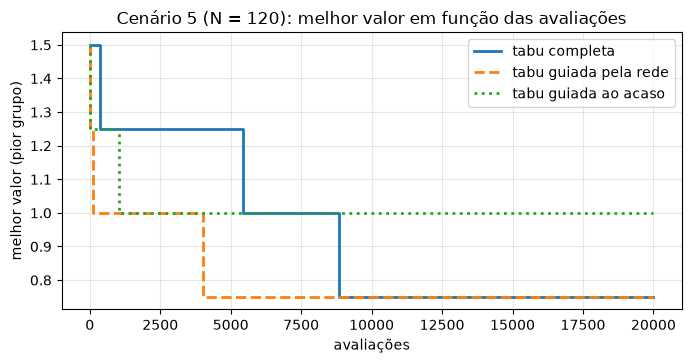

In [14]:
# Executar esta célula

fig, ax = plt.subplots(figsize=(8, 3.6))
for nome, estilo in zip(VERSOES, ("-", "--", ":")):
    x, y = zip(*historicos[(5, 20_000, nome)])
    ax.step(x, y, where="post", linestyle=estilo, linewidth=2, label=nome)
ax.set_xlabel("avaliações")
ax.set_ylabel("melhor valor (pior grupo)")
ax.set_title("Cenário 5 (N = 120): melhor valor em função das avaliações")
ax.legend()
plt.show()

### 5.7 O que os resultados mostram

- **Em avaliações, a rede ganha.** Com 5 mil avaliações, a tabu guiada pela rede chega a valores que a tabu completa ainda não alcançou, porque gasta 20 avaliações por iteração em vez de centenas e faz muitas mais iterações. Com 20 mil, a tabu completa já a alcançou.
- **A aprendizagem é que faz a diferença.** A tabu guiada ao acaso também faz muitas iterações, mas escolhe mal os movimentos a avaliar e fica atrás. O grupo de controlo mostra que a rede aprendeu algo útil.
- **Em tempo de CPU, a rede perde.** Calcular as características de todos os movimentos e passá-las pela rede custa mais do que avaliá-los diretamente, porque a avaliação incremental do N3_08 é muito barata. Com o mesmo tempo, a tabu completa faz muito mais avaliações e acaba à frente (no N3_08, chegou a 0,5 no cenário 5 em cerca de 4 segundos).

A conclusão não é que a rede «não funciona», mas que **neste problema avaliar é barato**, e a aprendizagem poupa o recurso errado.

## 6. Quando compensa aprender?

Juntando os resultados deste módulo e do N3_08:

| Situação | O que tende a funcionar melhor |
| --- | --- |
| Uma instância, avaliação barata (o nosso caso) | uma boa heurística com pesquisa local (pesquisa tabu, recozimento) |
| Avaliação **cara**: uma simulação, um ensaio, compilar e testar um programa | modelos que evitam avaliações inúteis: modelos substitutos, redes que filtram candidatos, como na secção 5 |
| **Muitas instâncias parecidas**, resolvidas todos os dias (rotas de entregas, horários) | aprender entre instâncias: o custo do treino divide-se por muitos problemas |
| Decisões em tempo real, sem tempo para pesquisar | uma política aprendida (por exemplo, por aprendizagem por reforço) que decide de imediato |
| Espaço grande e pouco estruturado | algoritmos de população combinados com pesquisa local (meméticos) |

**O estado da arte.** A investigação em «aprendizagem para otimização combinatória» usa sobretudo **redes neuronais de grafos**, que recebem o problema inteiro como um grafo (alunos como nós, incompatibilidades como arestas), e **aprendizagem por reforço**, em que a rede aprende uma política de decisão por tentativa e erro, sem precisar de um especialista para imitar. Estes métodos já dão bons resultados em problemas como o do caixeiro-viajante, mas exigem muito mais dados, código e tempo de treino do que cabe num notebook. A secção 5 mostra a ideia central numa versão pequena: **um modelo aprende com decisões passadas a escolher onde vale a pena procurar**.

## 7. Experimenta

### Exercício 1 – Convergência prematura na entropia cruzada

Corre a `entropia_cruzada` no cenário 3 com 5 segundos de CPU, para as combinações `alfa` = 0,3 e 0,9 com `eps` = 0,0 e 0,05 (quatro execuções, semente 0). Para cada uma, mostra o valor e, para medir quanto o modelo «se fixou», a fração de afinidades do modelo final acima de 0,9. Usa `guardar_modelo` para obter o modelo da última geração (`info['gerações']`), ou altera a função para devolver `P`.

In [15]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

A forma mais simples é guardar o modelo em todas as gerações possíveis e ficar com o último:

```python
for alfa in (0.3, 0.9):
    for eps in (0.0, 0.05):
        orc = Orcamento(max_avaliacoes=10**9, max_cpu=5)
        _, valor, info, _, modelos = entropia_cruzada(A24, 24, orc, np.random.default_rng(0),
                                                      alfa=alfa, eps=eps, guardar_modelo=range(1, 10_000))
        P_final = modelos[info["gerações"]]
        fixado = (P_final[np.triu_indices(24, 1)] > 0.9).mean()
        print(f"alfa={alfa}, eps={eps}: valor {valor} | afinidades > 0,9: {fixado:.1%}")
```

Sem margem de exploração (`eps=0`), o modelo fixa-se numa única divisão: 8,7 % das afinidades ficam acima de 0,9, que são exatamente os 24 pares dos 8 grupos (24 de 276 pares). A partir daí, gera sempre a mesma divisão. Com `alfa=0.9`, fixa-se cedo, numa divisão má (1,5); com `alfa=0.3`, fixa-se mais tarde, e nesta semente numa boa (1,0), mas foi sorte. Com `eps=0.05`, nenhum par fica com probabilidade zero, o modelo nunca se fixa e o resultado (1,25) é mais estável. É o dilema **exploração contra aproveitamento**, que aparece em todos os métodos de aprendizagem: explorar mais protege contra os maus resultados, mas pode atrasar os bons.

</details>

### Exercício 2 – Sem elitismo

Corre o `algoritmo_genetico` no cenário 3 (5 segundos de CPU, sementes 0 e 1) com `elite=2` e com `elite=0`. Compara os valores. O que acontece às boas soluções quando não há elitismo?

In [16]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for elite in (2, 0):
    valores = []
    for semente in (0, 1):
        orc = Orcamento(max_avaliacoes=10**9, max_cpu=5)
        _, valor, _, _ = algoritmo_genetico(A24, 24, orc, np.random.default_rng(semente), elite=elite)
        valores.append(valor)
    print(f"elite={elite}: {valores}")
```

Sem elitismo, o resultado é muito pior (cerca de 6, contra 1,25). As boas soluções de uma geração perdem-se, porque os seus filhos são quase sempre piores: o cruzamento e a mutação estragam mais do que melhoram. A população vai-se degradando, e o valor devolvido é o da última população. Com elitismo, as melhores soluções passam sempre à geração seguinte, e a população nunca piora.

</details>

### Exercício 3 – Quantos movimentos avaliar?

Na `tabu_guiada`, o parâmetro `k` diz quantos movimentos são avaliados por iteração. Corre-a no cenário 4 com 5 mil avaliações para `k` = 5, 20 e 80, e mostra o valor e o tempo de CPU. Que compromisso observas?

In [17]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for k in (5, 20, 80):
    orc = Orcamento(max_avaliacoes=5_000)
    estado, info, _ = tabu_guiada(A60, divisao_gulosa(A60, 60), orc, pontuar_rede, k=k)
    print(f"k={k:2d}: valor {estado.valor()} | {info['iterações']} iterações | {orc.cpu():.2f} s")
```

Com `k=5` o resultado piora (1,0 contra 0,75): há muitas iterações, mas a pesquisa depende muito dos erros da rede, e se o melhor movimento não estiver entre os 5 primeiros, nunca é visto. Com `k` grande, a rede quase não filtra e a pesquisa aproxima-se da tabu completa, com menos iterações para o mesmo orçamento. O tempo de CPU cresce com o número de iterações, porque cada iteração calcula as características de toda a vizinhança.

</details>

## Verifica o que aprendeste

1. Qual é a diferença entre aprender **durante** a pesquisa e aprender **entre** problemas? Dá um exemplo de cada neste módulo.
2. Quais são os quatro passos do método da entropia cruzada, e o que representa o seu modelo neste problema?
3. Para que servem a taxa $\alpha$ e a margem $\varepsilon$ na atualização do modelo?
4. Porque é que o cruzamento clássico (cortar duas listas ao meio) não serve para problemas de agrupamento, e o que faz o cruzamento usado aqui?
5. O que é o elitismo, e o que é um algoritmo memético?
6. Porque é que a comparação da secção 4 usa tempo de CPU e não o número de avaliações?
7. Porque é que as características da rede não podem incluir o custo dos grupos depois do movimento?
8. Porque é que se testa a rede numa turma diferente das de treino?
9. Para que serve a tabu guiada ao acaso?
10. Em que medida a tabu guiada pela rede é melhor do que a tabu completa, e em que medida é pior? Porquê?
11. Indica duas situações em que aprender para otimizar tende a compensar.

<details>
<summary><b>Ver respostas</b></summary>

1. Durante a pesquisa, aprende-se sobre a instância que se está a resolver, e o conhecimento não serve para outras (entropia cruzada, algoritmo genético). Entre problemas, aprende-se com instâncias já resolvidas algo que serve para novas (a rede que imita a tabu).
2. Amostrar uma população com o modelo, avaliá-la, selecionar a elite e atualizar o modelo com base na elite. O modelo é uma matriz de afinidades entre pares de alunos, que diz o quanto cada par costuma ficar junto nas boas divisões.
3. $\alpha$ controla a velocidade de aprendizagem (quanto do modelo antigo se substitui pelo que a elite ensina). $\varepsilon$ impede que um par fique com probabilidade zero, mantendo a exploração e evitando a convergência prematura.
4. Porque produz filhos com alunos repetidos ou em falta e desfaz os grupos, que são o que tem valor. O cruzamento usado passa grupos inteiros dos pais para o filho e repara os alunos que sobram.
5. O elitismo passa as melhores soluções de cada geração diretamente para a seguinte, para não se perderem. Um algoritmo memético é um algoritmo genético em que os filhos são melhorados por pesquisa local.
6. Porque as avaliações têm custos muito diferentes: na entropia cruzada e no algoritmo genético cada avaliação é uma divisão completa; na tabu, é um movimento avaliado de forma incremental.
7. Porque calcular esse custo é precisamente avaliar o movimento, e o objetivo da rede é evitar avaliações.
8. Para verificar que a rede aprendeu padrões gerais do problema e não as particularidades das turmas de treino (generalização).
9. É o grupo de controlo: tem a mesma vantagem de avaliar poucos movimentos por iteração, mas sem aprendizagem. Se a rede for melhor do que o controlo, o mérito é da aprendizagem.
10. Com o mesmo número de avaliações, chega mais longe, porque avalia poucos movimentos por iteração e faz mais iterações. Com o mesmo tempo de CPU, fica atrás, porque calcular as características e usar a rede custa mais do que a avaliação incremental, que neste problema é muito barata.
11. Por exemplo: quando cada avaliação é cara (uma simulação, um ensaio); quando se resolvem muitas instâncias parecidas, e o custo do treino se reparte por todas; quando é preciso decidir em tempo real.

</details>

## Leitura recomendada

- Rubinstein, R. Y. e Kroese, D. P. (2004). *The Cross-Entropy Method: A Unified Approach to Combinatorial Optimization, Monte-Carlo Simulation and Machine Learning*. Nova Iorque: Springer.
- Goldberg, D. E. (1989). *Genetic Algorithms in Search, Optimization, and Machine Learning*. Reading: Addison-Wesley. Uma introdução clássica aos algoritmos genéticos.
- Falkenauer, E. (1998). *Genetic Algorithms and Grouping Problems*. Chichester: Wiley. A origem do cruzamento por grupos usado na secção 3.
- Moscato, P. (1989). *On Evolution, Search, Optimization, Genetic Algorithms and Martial Arts: Towards Memetic Algorithms*. Caltech Concurrent Computation Program, relatório 826. O texto que propôs os algoritmos meméticos.
- Bengio, Y., Lodi, A. e Prouvost, A. (2021). [Machine learning for combinatorial optimization: a methodological tour d'horizon](https://doi.org/10.1016/j.ejor.2020.07.063). *European Journal of Operational Research*, 290(2), 405–421. Uma visão geral de como a aprendizagem automática é usada em otimização combinatória, incluindo a aprendizagem por imitação.
- Russell, S. e Norvig, P. (2021). *[Artificial Intelligence: A Modern Approach](https://aima.cs.berkeley.edu/)* (4.ª ed.). Hoboken: Pearson. Capítulo 4 (algoritmos genéticos e pesquisa local) e capítulos 19 a 22 (aprendizagem).
- **Módulos relacionados:** N3_08 (o problema e os algoritmos de pesquisa), N3_04 e N3_05 (redes neuronais).